# 07. 개선 실험: 클래스 가중치(E07c·E07d)

**문제**: 바벨 로우(Train 312장, 가장 적음)가 여러 실행에서 통째로 사라졌습니다(E05a·E05c·E05e·E07a, Recall 0.00~0.03).

**방법**: 학습 손실(CrossEntropy)에 클래스 가중치 w_c = N / (K · n_c)를 줍니다. 적은 클래스를 틀리면 손실이 더 커지므로, 모델이 그 클래스를 포기하기 어려워집니다.
- 바벨 로우 2.18, Y-Exercise·바이시클 크런치 2.12, 케이블 크런치 1.51 / 로잉머신 0.61 등
- Σ n_c · w_c = N이라 손실의 전체 크기는 가중치가 없을 때와 비슷합니다.
- Val 손실은 가중치 없이 계산합니다(다른 실험과 같은 기준). 입력은 기본 224입니다.

**가설**: 바벨 로우 Recall이 오르고, 다른 클래스의 Recall은 0.15 넘게 떨어지지 않을 것이다. 판정 기준은 실행 전에 `experiments/E07/PLAN.md` 2절에 적었습니다(Val Macro F1 기본 대비 +0.02 이상 개선).

**주의**: 가중치는 "Train에 적다"는 정보만 반영합니다. Val의 바벨 로우가 Train과 다른 특이 자세를 포함한다는 문제(E06)는 가중치로 해결되지 않습니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font
from dataset import balanced_class_weights

print("font:", set_korean_font())
pd.set_option("display.width", 180)
NAMES = class_names()
PAIRS = [("full", "E04", "E07c"), ("scratch", "E01", "E07d")]
LABEL = {"full": "Full FT", "scratch": "Scratch"}
def load(rid, s):
    d = ROOT / "experiments" / rid / s
    return pd.read_csv(d / "history.csv"), json.loads((d / "summary.json").read_text(encoding="utf-8"))
R = {rid: load(rid, s) for s, b, n in PAIRS for rid in (b, n)}
def verdict(x):
    return "개선" if x >= 0.02 else ("악화" if x <= -0.02 else "차이 없음")
w = balanced_class_weights()
pd.DataFrame({"클래스": [f"{c} {NAMES[c]}" for c in range(12)], "가중치": w.numpy().round(2)}).set_index("클래스").T

font: Malgun Gothic


클래스,0 Y - Exercise,1 니푸쉬업,2 덤벨 벤트오버 로우,3 딥스,4 라잉 레그 레이즈,5 랫풀 다운,6 로잉머신,7 바벨 데드리프트,8 바벨 런지,9 바벨 로우,10 바이시클 크런치,11 케이블 크런치
가중치,2.12,0.85,0.85,0.76,1.06,0.76,0.61,0.85,0.85,2.18,2.12,1.51


## 1. 전체 결과

In [2]:
rows = []
for s, base, new in PAIRS:
    for rid in (base, new):
        h, sm = R[rid]
        d = sm["val"]["macro_f1"] - R[base][1]["val"]["macro_f1"]
        b = h[h.epoch == sm["best_epoch"]].iloc[0]
        rows.append({"전략": LABEL[s], "실행": rid, "클래스 가중치": "balanced" if rid == new else "없음",
                     "Val Macro F1": round(sm["val"]["macro_f1"], 4), "Val Acc": round(sm["val"]["accuracy"], 4),
                     "기본 대비": round(d, 4), "판정": "" if rid == base else verdict(d),
                     "최고/멈춘 epoch": f"{sm['best_epoch']}/{sm['epochs_run']}", "최고 시점 Train Acc": round(b.train_acc, 3),
                     "총 시간(분)": round(sm["total_time_s"] / 60, 1)})
pd.DataFrame(rows)

,전략,실행,클래스 가중치,Val Macro F1,Val Acc,기본 대비,판정,최고/멈춘 epoch,최고 시점 Train Acc,총 시간(분)
0,Full FT,E04,없음,0.8581,0.8660,0.0000,,16/21,0.998,4.4
1,Full FT,E07c,balanced,0.8370,0.8375,-0.0211,악화,3/8,0.964,1.8
2,Scratch,E01,없음,0.7928,0.7979,0.0000,,9/14,0.952,3.0
3,Scratch,E07d,balanced,0.7451,0.7597,-0.0477,악화,14/19,0.977,4.1


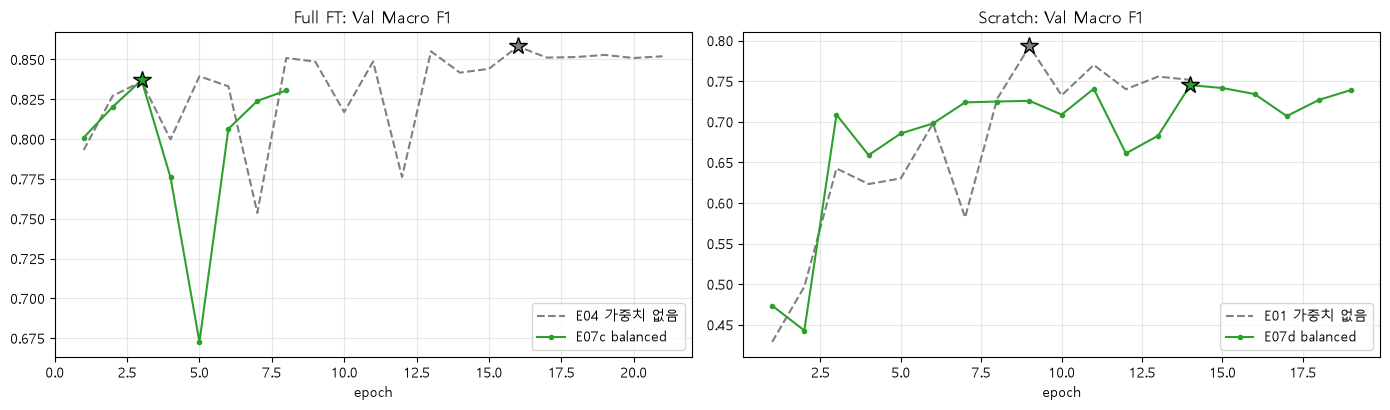

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (s, base, new) in zip(axes, PAIRS):
    for rid, sty, col, lab in ((base, "--", "gray", "가중치 없음"), (new, "-", "C2", "balanced")):
        h, sm = R[rid]
        ax.plot(h.epoch, h.val_macro_f1, sty, color=col, marker="." if rid == new else None, label=f"{rid} {lab}")
        ax.plot(sm["best_epoch"], sm["val"]["macro_f1"], "*", ms=13, color=col, mec="k")
    ax.set_title(f"{LABEL[s]}: Val Macro F1"); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "e07cd_curves.png", dpi=100); plt.show()

## 2. 가설 확인: 클래스별 Recall 변화(가중치 − 기본)

In [4]:
order = [c for g in GROUPS.values() for c in g]
rows = []
for c in order:
    row = {"클래스": f"{c} {NAMES[c]}", "가중치": round(float(w[c]), 2)}
    for s, base, new in PAIRS:
        rb = R[base][1]["val"]["per_class"]["recall"][NAMES[c]]; rn = R[new][1]["val"]["per_class"]["recall"][NAMES[c]]
        row[f"{LABEL[s]} 기본"] = round(rb, 3); row[f"{LABEL[s]} 가중치"] = round(rn, 3); row[f"{LABEL[s]} 변화"] = round(rn - rb, 3)
    rows.append(row)
rec = pd.DataFrame(rows).set_index("클래스")
for s, base, new in PAIRS:
    drop = rec[rec[f"{LABEL[s]} 변화"] < -0.15].index.tolist()
    print(f"{LABEL[s]}: 바벨 로우 Recall {rec.loc['9 바벨 로우', f'{LABEL[s]} 기본']} → {rec.loc['9 바벨 로우', f'{LABEL[s]} 가중치']}, Recall이 0.15 넘게 떨어진 클래스: {drop or '없음'}")
rec

Full FT: 바벨 로우 Recall 0.531 → 0.719, Recall이 0.15 넘게 떨어진 클래스: ['2 덤벨 벤트오버 로우']
Scratch: 바벨 로우 Recall 0.5 → 0.328, Recall이 0.15 넘게 떨어진 클래스: ['10 바이시클 크런치', '7 바벨 데드리프트', '9 바벨 로우']


,가중치,Full FT 기본,Full FT 가중치,Full FT 변화,Scratch 기본,Scratch 가중치,Scratch 변화
클래스,,,,,,,
0 Y - Exercise,2.12,0.969,0.984,0.016,0.906,0.891,-0.016
1 니푸쉬업,0.85,1.000,1.000,0.000,1.000,1.000,0.000
4 라잉 레그 레이즈,1.06,0.852,0.867,0.016,0.906,0.828,-0.078
10 바이시클 크런치,2.12,0.969,0.953,-0.016,0.641,0.484,-0.156
2 덤벨 벤트오버 로우,0.85,0.794,0.475,-0.319,0.512,0.619,0.106
7 바벨 데드리프트,0.85,0.400,0.375,-0.025,0.444,0.225,-0.219
8 바벨 런지,0.85,0.950,0.994,0.044,0.750,0.731,-0.019
9 바벨 로우,2.18,0.531,0.719,0.188,0.500,0.328,-0.172
3 딥스,0.76,1.000,1.000,0.000,1.000,1.000,0.000


In [5]:
rows = []
for s, base, new in PAIRS:
    for rid in (base, new):
        cm = np.array(R[rid][1]["val"]["confusion_matrix"])
        rows.append({"전략": LABEL[s], "실행": rid, "7→9": cm[7, 9], "9→7": cm[9, 7], "9→2": cm[9, 2], "2→9": cm[2, 9],
                     "7→2": cm[7, 2], "2→7": cm[2, 7], "9로 예측한 총 장수": cm[:, 9].sum(), "바벨 로우 Precision": round(cm[9, 9] / max(cm[:, 9].sum(), 1), 3)})
print("바벨·덤벨 묶음 혼동(정답→예측 장수). Val 바벨 로우는 64장")
pd.DataFrame(rows)

바벨·덤벨 묶음 혼동(정답→예측 장수). Val 바벨 로우는 64장


,전략,실행,7→9,9→7,9→2,2→9,7→2,2→7,9로 예측한 총 장수,바벨 로우 Precision
0,Full FT,E04,82,13,11,21,14,3,138,0.246
1,Full FT,E07c,93,2,11,61,5,8,201,0.229
2,Scratch,E01,30,17,7,6,53,45,69,0.464
3,Scratch,E07d,10,4,35,3,104,18,34,0.618


## 3. 해석

### 3.1 판정: 두 방식 모두 악화

| 실행 | Val Macro F1 | 기본 대비 | 판정 | 바벨 로우 Recall | Recall이 0.15 넘게 떨어진 클래스 |
|---|---|---|---|---|---|
| E07c Full FT + 가중치 | 0.837 | −0.021 | 악화 | 0.53 → 0.72 | 덤벨 로우(0.79 → 0.48) |
| E07d Scratch + 가중치 | 0.745 | −0.048 | 악화 | 0.50 → 0.33 | 바이시클 크런치, 데드리프트, 바벨 로우 |

클래스 가중치는 채택하지 않습니다.

### 3.2 Full FT: 바벨 로우를 "더 자주 말하게" 됐을 뿐입니다

- 가설의 앞부분은 맞았습니다. 바벨 로우 Recall이 0.53 → 0.72로 올랐습니다.
- 그런데 모델이 바벨 로우라고 예측한 사진이 138장 → **201장**으로 늘었습니다(Val의 바벨 로우는 64장). 덤벨 로우 → 바벨 로우가 21 → 61장, 데드리프트 → 바벨 로우가 82 → 93장입니다. 바벨 로우 Precision은 0.25 → 0.23으로 오히려 낮아졌습니다.
- 가중치는 "애매하면 바벨 로우 쪽으로 기울어라"는 신호입니다. 2·7·9 사이가 애매한 사진이 많으니, 그 사진들이 한꺼번에 바벨 로우로 쏠렸습니다. **모델이 세 운동을 더 잘 구분하게 된 것이 아니라, 애매한 사진의 기본값을 바꾼 것**입니다.

### 3.3 Scratch: 가중치를 줬는데 바벨 로우가 오히려 줄었습니다

- 바벨 로우 Recall이 0.50 → 0.33으로 내려갔습니다. 대신 데드리프트 → 덤벨 로우가 53 → 104장으로 늘었습니다.
- 가중치가 학습 경로 전체를 바꿔서, 결과는 가중치의 의도와 다른 방향으로 갔습니다. Scratch는 Val 곡선이 크게 출렁이는 방식이라(0.66~0.75), 이 실행 하나로 "가중치가 Scratch에 해롭다"고 일반화하지는 않습니다.

### 3.4 E05~E07 전체에서 보이는 것: 묶음 안 경계가 불안정합니다

| 실행 | 바꾼 것 | 데드리프트 Recall | 덤벨 로우 Recall | 바벨 로우 Recall | Macro F1 |
|---|---|---|---|---|---|
| E04 | 기본(Full) | 0.40 | 0.79 | 0.53 | 0.858 |
| E05d | 증강 | 0.59 | 0.66 | 0.58 | 0.870 |
| E07a | 해상도 384 | 0.85 | 0.97 | 0.03 | 0.873 |
| E07c | 클래스 가중치 | 0.38 | 0.48 | 0.72 | 0.837 |

- 무엇을 바꾸든 **세 운동 중 하나가 좋아지면 다른 하나가 나빠집니다.** 오류가 사라지지 않고 자리를 옮깁니다.
- Full FT에서 바벨·덤벨 묶음 밖(맨몸·기구)은 실행마다 상대적으로 작게 움직입니다(클래스별 Recall 변화 대부분 ±0.05 안, 가장 큰 것은 E07c 케이블 크런치 −0.11). 그래서 Macro F1의 차이는 대부분 이 세 클래스가 어떻게 나뉘었는지로 정해집니다.
- 원인은 두 가지가 겹친 것으로 봅니다.
  1. 정지 사진 한 장으로는 정보가 부족한 프레임이 많습니다(E06).
  2. Val의 바벨·덤벨 묶음이 한 사람(Z23)이고, 바벨 로우는 64장(8클립)뿐이며, Train에 드문 자세가 섞여 있습니다.
- 그래서 Val 점수 0.84~0.87 사이의 차이는 **"더 좋은 모델"보다 "애매한 사진을 어느 쪽으로 보냈는가"를 반영할 가능성이 큽니다.** 최종 선정(U-12)에서 단일 실행의 0.01~0.02 차이로 고르지 않아야 하는 근거입니다.

### 3.5 개선 실험 단계 정리

- 공식 요구(개선 실험 최소 1회)는 충족했습니다. 해상도(E07a·b)와 클래스 가중치(E07c·d) 두 가설을 시험했고, 미리 정한 기준을 넘은 것은 없습니다.
- 실패한 실험도 모두 기록에 남깁니다. "왜 안 됐는가"(경계 불안정, Val 구성)가 이 프로젝트의 중요한 결론입니다.